# 01 — Comparação geral do NSE nas 8 bacias

Este notebook compara, no mesmo período de teste, três cenários:

1. **INDIVIDUAL** — cada uma das 8 bacias treinada separadamente (8 CSVs);
2. **MULTI_8** — uma rede treinada conjuntamente com as 8 bacias (1 CSV consolidado);
3. **MULTI_39** — uma rede treinada com 39 bacias, mas avaliada nas mesmas 8 bacias (1 CSV consolidado).

O leitor aceita CSV separado por `,`, `;`, tabulação ou espaços. Ele reconhece nomes comuns como `gauge_id`, `basin`, `NSE`, `NSE_bacia`, `streamflow_m3s_obs` e `streamflow_m3s_sim`.

Formato mínimo para este notebook: `bacia` + `NSE`. Se o NSE não existir, ele será calculado a partir de `qobs` e `qsim`.

Estrutura sugerida:

```text
dados_resultados/
├── individual/
│   ├── 8XXXXX.csv
│   ├── 8XXXXX.csv
│   └── ... (N arquivos)
├── multibacia_X.csv
└── multibacia_XX.csv
```


In [ ]:
from pathlib import Path
import math
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)

PASTA_DADOS = Path("dados_resultados")
PASTA_SAIDA = Path("saidas_metricas_gerais")

CONFIGURACOES = {
    "INDIVIDUAL": {
        "tipo": "pasta",
        "caminho": PASTA_DADOS / "individual",
    },
    "MULTI_8": {
        "tipo": "arquivo",
        "caminho": PASTA_DADOS / "multibacia_8.csv",
    },
    "MULTI_39": {
        "tipo": "arquivo",
        "caminho": PASTA_DADOS / "multibacia_39.csv",
    },
}

# Se deixar vazio, as bacias serão detectadas automaticamente.
# Para fixar exatamente as 8, use: ["70100000", "...", ...]
BACIAS_AVALIACAO = []

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)


In [13]:
def normalizar_nome_coluna(nome):
    """Remove acentos e padroniza o nome para facilitar o reconhecimento."""
    texto = unicodedata.normalize("NFKD", str(nome))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = re.sub(r"[^a-zA-Z0-9]+", "_", texto.lower()).strip("_")
    return texto


ALIASES = {
    "bacia": [
        "bacia", "basin", "basin_id", "gauge_id", "gauge", "station_id",
        "codigo_bacia", "codigo_estacao"
    ],
    "data": ["data", "date", "datetime", "time", "tempo"],
    "qobs_m3s": [
        "qobs_m3s", "streamflow_m3s_obs", "qobs", "q_obs", "obs",
        "observado", "observada", "vazao_observada", "vazao_obs"
    ],
    "qsim_m3s": [
        "qsim_m3s", "streamflow_m3s_sim", "qsim", "q_sim", "sim",
        "simulado", "simulada", "vazao_simulada", "vazao_sim"
    ],
    "NSE": ["nse", "NSE_bacia", "nse_bacia", "nash_sutcliffe", "nash_sutcliffe_efficiency"],
}


def ler_csv_robusto(caminho):
    """Lê CSV separado por vírgula, ponto e vírgula, tabulação ou espaços."""
    caminho = Path(caminho)
    tentativas = [
        {"sep": None, "engine": "python", "decimal": ","},
        {"sep": ";", "engine": "python", "decimal": ","},
        {"sep": "\t", "engine": "python", "decimal": ","},
        {"sep": r"\s+", "engine": "python", "decimal": "."},
        {"sep": ",", "engine": "python", "decimal": "."},
    ]

    melhor = None
    melhor_chave = (-1, -1)
    erros = []
    nomes_reconhecidos = {
        alias
        for aliases in ALIASES.values()
        for alias in aliases
    }
    for argumentos in tentativas:
        try:
            candidato = pd.read_csv(
                caminho,
                dtype=str,
                encoding="utf-8-sig",
                **argumentos,
            )
            colunas_normalizadas = {
                normalizar_nome_coluna(c) for c in candidato.columns
            }
            pontuacao = len(colunas_normalizadas.intersection(nomes_reconhecidos))
            chave = (pontuacao, candidato.shape[1])
            if melhor is None or chave > melhor_chave:
                melhor = candidato
                melhor_chave = chave
        except Exception as erro:
            erros.append(str(erro))

    if melhor is None:
        raise ValueError(f"Não foi possível ler {caminho}. Erros: {erros[:2]}")

    melhor.columns = [str(c).strip() for c in melhor.columns]
    return melhor


def para_numero(serie):
    texto = serie.astype(str).str.strip()
    texto = texto.replace({"": np.nan, "nan": np.nan, "None": np.nan, "-": np.nan})
    texto = texto.str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")


def para_data(serie):
    """Reconhece datas ISO (ano-mês-dia) e datas brasileiras (dia/mês/ano)."""
    texto = serie.astype(str).str.strip()
    amostra = texto[~texto.isin(["", "nan", "None"])]
    proporcao_iso = amostra.str.match(r"^\d{4}[-/]\d{1,2}[-/]\d{1,2}").mean()
    if pd.notna(proporcao_iso) and proporcao_iso >= 0.8:
        return pd.to_datetime(texto, errors="coerce", yearfirst=True)
    return pd.to_datetime(texto, errors="coerce", dayfirst=True)


def padronizar_colunas(df, caminho):
    """Converte nomes usuais do NeuralHydrology para os nomes usados aqui."""
    df = df.copy()
    normalizadas = {normalizar_nome_coluna(c): c for c in df.columns}
    renomear = {}

    for destino, aliases in ALIASES.items():
        for alias in aliases:
            if alias in normalizadas:
                renomear[normalizadas[alias]] = destino
                break

    df = df.rename(columns=renomear)

    if "bacia" not in df.columns:
        encontrados = re.findall(r"(?<!\d)(\d{7,8})(?!\d)", Path(caminho).stem)
        if encontrados:
            df["bacia"] = encontrados[-1]
        else:
            raise ValueError(
                f"{Path(caminho).name}: não encontrei a coluna da bacia e "
                "o nome do arquivo não contém um código de 7 ou 8 dígitos."
            )

    df["bacia"] = (
        df["bacia"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
    )

    for coluna in ["qobs_m3s", "qsim_m3s", "NSE"]:
        if coluna in df.columns:
            df[coluna] = para_numero(df[coluna])

    if "data" in df.columns:
        df["data"] = para_data(df["data"])

    return df


def listar_arquivos(especificacao):
    caminho = Path(especificacao["caminho"])
    tipo = especificacao["tipo"].lower()

    if tipo == "pasta":
        if not caminho.exists():
            raise FileNotFoundError(f"Pasta não encontrada: {caminho.resolve()}")
        arquivos = sorted(caminho.glob("*.csv"))
        if not arquivos:
            raise FileNotFoundError(f"Nenhum CSV encontrado em: {caminho.resolve()}")
        return arquivos

    if tipo == "arquivo":
        if not caminho.exists():
            raise FileNotFoundError(f"Arquivo não encontrado: {caminho.resolve()}")
        return [caminho]

    raise ValueError("O campo 'tipo' deve ser 'pasta' ou 'arquivo'.")


def carregar_configuracao(nome, especificacao):
    partes = []
    for caminho in listar_arquivos(especificacao):
        df = padronizar_colunas(ler_csv_robusto(caminho), caminho)
        df["arquivo_origem"] = caminho.name
        partes.append(df)

    resultado = pd.concat(partes, ignore_index=True, sort=False)
    resultado["configuracao"] = nome
    return resultado


In [17]:
def calcular_nse(qobs, qsim):
    qobs = np.asarray(qobs, dtype=float)
    qsim = np.asarray(qsim, dtype=float)
    validos = np.isfinite(qobs) & np.isfinite(qsim)
    qobs = qobs[validos]
    qsim = qsim[validos]

    if qobs.size < 2:
        return np.nan

    denominador = np.sum((qobs - np.mean(qobs)) ** 2)
    if denominador == 0:
        return np.nan

    return 1 - np.sum((qsim - qobs) ** 2) / denominador


def extrair_nse(df):
    registros = []

    for bacia, grupo in df.groupby("bacia", sort=True):
        valores_nse = pd.Series(dtype=float)
        if "NSE" in grupo.columns:
            valores_nse = grupo["NSE"].dropna()

        if not valores_nse.empty:
            unicos = np.unique(np.round(valores_nse.to_numpy(dtype=float), 12))
            if len(unicos) > 1:
                warnings.warn(
                    f"A bacia {bacia}, configuração {grupo['configuracao'].iloc[0]}, "
                    f"possui mais de um NSE ({unicos}). Será usado o primeiro."
                )
            nse = float(valores_nse.iloc[0])
            fonte = "CSV"
        elif {"qobs_m3s", "qsim_m3s"}.issubset(grupo.columns):
            nse = calcular_nse(grupo["qobs_m3s"], grupo["qsim_m3s"])
            fonte = "calculado"
        else:
            raise ValueError(
                f"Não existe NSE nem qobs/qsim para a bacia {bacia} em "
                f"{grupo['configuracao'].iloc[0]}."
            )

        registros.append({
            "bacia": str(bacia),
            "configuracao": grupo["configuracao"].iloc[0],
            "NSE": nse,
            "fonte_NSE": fonte,
            "arquivo_origem": ", ".join(sorted(grupo["arquivo_origem"].unique())),
        })

    return pd.DataFrame(registros)


partes_nse = []
for nome, especificacao in CONFIGURACOES.items():
    dados = carregar_configuracao(nome, especificacao)
    partes_nse.append(extrair_nse(dados))

nse_longo = pd.concat(partes_nse, ignore_index=True)

disponiveis = {
    nome: set(nse_longo.loc[nse_longo["configuracao"] == nome, "bacia"])
    for nome in CONFIGURACOES
}

if BACIAS_AVALIACAO:
    bacias = [str(b).strip() for b in BACIAS_AVALIACAO]
else:
    bacias = sorted(set().union(*disponiveis.values()))

faltantes = []
for nome, conjunto in disponiveis.items():
    for bacia in bacias:
        if bacia not in conjunto:
            faltantes.append({"configuracao": nome, "bacia_ausente": bacia})

if faltantes:
    print("Bacias ausentes em alguma configuração:")
    display(pd.DataFrame(faltantes))
    raise ValueError(
        "A comparação precisa das mesmas bacias nos três cenários. "
        "Corrija os arquivos ou preencha BACIAS_AVALIACAO."
    )

if len(bacias) != 8:
    warnings.warn(f"Foram detectadas {len(bacias)} bacias, e não 8: {bacias}")

nse_longo = nse_longo[nse_longo["bacia"].isin(bacias)].copy()
nse_longo["bacia"] = pd.Categorical(nse_longo["bacia"], categories=bacias, ordered=True)
nse_longo["configuracao"] = pd.Categorical(
    nse_longo["configuracao"], categories=list(CONFIGURACOES), ordered=True
)
nse_longo = nse_longo.sort_values(["bacia", "configuracao"]).reset_index(drop=True)

print(f"Bacias comparadas ({len(bacias)}): {', '.join(bacias)}")
display(nse_longo.round(4))


Bacias comparadas (8): 86100000, 86160000, 86410000, 86480000, 86500000, 86510000, 86560000, 86580000


,bacia,configuracao,NSE,fonte_NSE,arquivo_origem
0,86100000,INDIVIDUAL,0.7285,CSV,86100000.csv
1,86100000,MULTI_8,0.6955,CSV,multibacia_8.csv
2,86100000,MULTI_39,0.7837,CSV,multibacia_39.csv
3,86160000,INDIVIDUAL,0.7992,CSV,86160000.csv
4,86160000,MULTI_8,0.7221,CSV,multibacia_8.csv
5,86160000,MULTI_39,0.6915,CSV,multibacia_39.csv
6,86410000,INDIVIDUAL,0.8534,CSV,86410000.csv
7,86410000,MULTI_8,0.8571,CSV,multibacia_8.csv
8,86410000,MULTI_39,0.8135,CSV,multibacia_39.csv
9,86480000,INDIVIDUAL,0.8746,CSV,86480000.csv


In [18]:
# Tabela principal: uma linha por bacia e uma coluna por cenário
tabela_nse = (
    nse_longo.pivot(index="bacia", columns="configuracao", values="NSE")
    .reindex(index=bacias, columns=list(CONFIGURACOES))
    .reset_index()
)
tabela_nse.columns.name = None

# Ganhos: valor positivo significa melhora do cenário da esquerda sobre o da direita.
tabela_nse["ganho_MULTI_8_vs_INDIVIDUAL"] = (
    tabela_nse["MULTI_8"] - tabela_nse["INDIVIDUAL"]
)
tabela_nse["ganho_MULTI_39_vs_INDIVIDUAL"] = (
    tabela_nse["MULTI_39"] - tabela_nse["INDIVIDUAL"]
)
tabela_nse["ganho_MULTI_39_vs_MULTI_8"] = (
    tabela_nse["MULTI_39"] - tabela_nse["MULTI_8"]
)

colunas_cenarios = list(CONFIGURACOES)
tabela_nse["melhor_configuracao"] = (
    tabela_nse[colunas_cenarios].idxmax(axis=1)
)
tabela_nse["melhor_NSE"] = tabela_nse[colunas_cenarios].max(axis=1)

resumo_configuracoes = (
    nse_longo.groupby("configuracao", observed=True)["NSE"]
    .agg(
        n_bacias="count",
        NSE_medio="mean",
        NSE_mediano="median",
        desvio_padrao="std",
        NSE_minimo="min",
        NSE_maximo="max",
    )
    .reset_index()
)

contagens = (
    nse_longo.assign(
        NSE_positivo=nse_longo["NSE"] > 0,
        NSE_maior_igual_05=nse_longo["NSE"] >= 0.5,
    )
    .groupby("configuracao", observed=True)[["NSE_positivo", "NSE_maior_igual_05"]]
    .sum()
    .reset_index()
)
resumo_configuracoes = resumo_configuracoes.merge(contagens, on="configuracao")

print("Tabela comparativa por bacia:")
display(tabela_nse.round(4))

print("Resumo dos cenários:")
display(resumo_configuracoes.round(4))

print("Número de bacias em que cada cenário foi o melhor:")
display(
    tabela_nse["melhor_configuracao"]
    .value_counts()
    .reindex(colunas_cenarios, fill_value=0)
    .rename_axis("configuracao")
    .reset_index(name="numero_de_vitorias")
)


Tabela comparativa por bacia:


,bacia,INDIVIDUAL,MULTI_8,MULTI_39,ganho_MULTI_8_vs_INDIVIDUAL,ganho_MULTI_39_vs_INDIVIDUAL,ganho_MULTI_39_vs_MULTI_8,melhor_configuracao,melhor_NSE
0,86100000,0.7285,0.6955,0.7837,-0.0330,0.0552,0.0881,MULTI_39,0.7837
1,86160000,0.7992,0.7221,0.6915,-0.0771,-0.1077,-0.0306,INDIVIDUAL,0.7992
2,86410000,0.8534,0.8571,0.8135,0.0037,-0.0399,-0.0436,MULTI_8,0.8571
3,86480000,0.8746,0.8723,0.8580,-0.0023,-0.0166,-0.0143,INDIVIDUAL,0.8746
4,86500000,0.7513,0.7572,0.7347,0.0059,-0.0166,-0.0225,MULTI_8,0.7572
5,86510000,0.8526,0.8639,0.8515,0.0113,-0.0011,-0.0124,MULTI_8,0.8639
6,86560000,0.8224,0.8307,0.7489,0.0083,-0.0735,-0.0818,MULTI_8,0.8307
7,86580000,0.7225,0.7854,0.7297,0.0629,0.0073,-0.0556,MULTI_8,0.7854


Resumo dos cenários:


,configuracao,n_bacias,NSE_medio,NSE_mediano,desvio_padrao,NSE_minimo,NSE_maximo,NSE_positivo,NSE_maior_igual_05
0,INDIVIDUAL,8,0.8006,0.8108,0.0600,0.7225,0.8746,8,8
1,MULTI_8,8,0.7980,0.8080,0.0682,0.6955,0.8723,8,8
2,MULTI_39,8,0.7764,0.7663,0.0605,0.6915,0.8580,8,8


Número de bacias em que cada cenário foi o melhor:


,configuracao,numero_de_vitorias
0,INDIVIDUAL,2
1,MULTI_8,5
2,MULTI_39,1


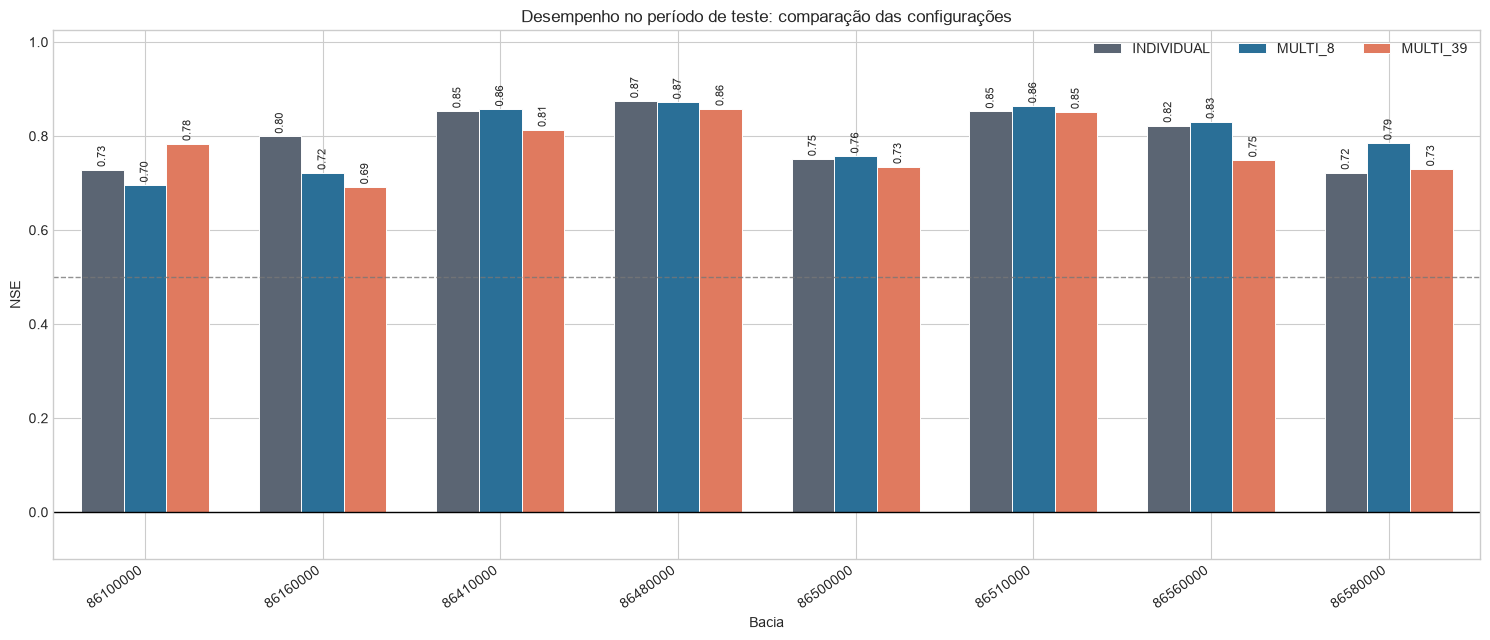

Figura salva em: B:\Codigos\NH_Avalacoes\AvalacoesTest1AUGM\saidas_metricas_gerais\comparacao_NSE_8_bacias.png


In [19]:
# Gráfico comparativo do NSE nas 8 bacias
cores = {
    "INDIVIDUAL": "#5B6573",
    "MULTI_8": "#2A6F97",
    "MULTI_39": "#E07A5F",
}

x = np.arange(len(bacias))
largura = 0.24

fig, ax = plt.subplots(figsize=(15, 6.5))
for indice, nome in enumerate(CONFIGURACOES):
    valores = tabela_nse[nome].to_numpy(dtype=float)
    deslocamento = (indice - 1) * largura
    barras = ax.bar(
        x + deslocamento,
        valores,
        width=largura,
        label=nome,
        color=cores[nome],
        edgecolor="white",
        linewidth=0.7,
    )
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8, rotation=90)

ax.axhline(0, color="black", linewidth=1)
ax.axhline(0.5, color="#777777", linewidth=1, linestyle="--", alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(bacias, rotation=35, ha="right")
ax.set_ylabel("NSE")
ax.set_xlabel("Bacia")
ax.set_title("Desempenho no período de teste: comparação das configurações")
ax.legend(frameon=False, ncol=3)
ax.margins(x=0.02)

menor = np.nanmin(tabela_nse[colunas_cenarios].to_numpy(dtype=float))
maior = np.nanmax(tabela_nse[colunas_cenarios].to_numpy(dtype=float))
ax.set_ylim(min(-0.1, menor - 0.12), max(1.0, maior + 0.15))

fig.tight_layout()
caminho_figura = PASTA_SAIDA / "comparacao_NSE_8_bacias.png"
fig.savefig(caminho_figura, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figura salva em: {caminho_figura.resolve()}")


In [20]:
# Exportação das tabelas
caminho_excel = PASTA_SAIDA / "metricas_gerais_8_bacias.xlsx"

try:
    with pd.ExcelWriter(caminho_excel, engine="openpyxl") as writer:
        tabela_nse.to_excel(writer, sheet_name="NSE_por_bacia", index=False)
        resumo_configuracoes.to_excel(writer, sheet_name="Resumo_configuracoes", index=False)
        nse_longo.to_excel(writer, sheet_name="Dados_longos", index=False)
    print(f"Excel salvo em: {caminho_excel.resolve()}")
except ImportError:
    print("Para criar o Excel, instale: %pip install openpyxl")

tabela_nse.to_csv(
    PASTA_SAIDA / "NSE_por_bacia.csv",
    sep=";", decimal=",", index=False, encoding="utf-8-sig"
)
resumo_configuracoes.to_csv(
    PASTA_SAIDA / "resumo_configuracoes.csv",
    sep=";", decimal=",", index=False, encoding="utf-8-sig"
)

print(f"CSVs salvos em: {PASTA_SAIDA.resolve()}")


Excel salvo em: B:\Codigos\NH_Avalacoes\AvalacoesTest1AUGM\saidas_metricas_gerais\metricas_gerais_8_bacias.xlsx
CSVs salvos em: B:\Codigos\NH_Avalacoes\AvalacoesTest1AUGM\saidas_metricas_gerais
